# From fabricated geometry to a calibrated measurement

Predict first: can a perfect calibration remove an unknown sample displacement? Can fabrication tolerances cancel when they are correlated? This notebook makes the assumed truth visible, then constructs synthetic observations.

**Every measurement here is synthetic.** The Lorentz material is illustrative; the resonator is an assigned one-port model, not a simulated fabricated patch. Ideal short/load/open standards illustrate calibration at a common one-port plane; they are not a free-space horn calibration recipe.

Use Python 3.12 and requirements-labs.txt. Run all cells in order. The last cell writes reference.json and synthetic-sweep.csv under data/chapter-09; preserve those files before editing. Plot labels and numerical outputs are shared by both language editions.

In [1]:
from pathlib import Path
from dataclasses import asdict, replace
import sys, json, hashlib, csv
import numpy as np
import matplotlib.pyplot as plt
ROOT=Path.cwd()
if not (ROOT/'simulations').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from simulations.materials_measurement import (Experiment, C0, lorentz, reflection,
    resonance, tolerance_samples, tolerance_linear_std, wilson, synthetic_sweep,
    uncertain_measurements, reference_factor, error_terms, measured)
p=Experiment()  # Edit physical and uncertainty assumptions here.
plt.rcParams.update({'figure.dpi':120,'font.size':10,'axes.spines.top':False,
    'axes.spines.right':False,'axes.grid':True,'grid.alpha':.2})
colors=['#087f8c','#e18431','#7252a1']
evidence={'metadata':{'parameters':asdict(p),'model':'synthetic one-port calibration and assigned resonator',
    'source_sha256':hashlib.sha256((ROOT/'simulations/materials_measurement.py').read_text(encoding='utf-8').encode()).hexdigest()}}
pack=lambda a:np.column_stack([np.asarray(a).real,np.asarray(a).imag]).tolist()
print(asdict(p))
print('Resonant absorption:',1-abs(reflection(p.resonance_GHz,p=p))**2)

{'resonance_GHz': 10.0, 'width_mm': 5.0, 'epsilon_eff': 3.0, 'external_GHz': 0.35, 'internal_GHz': 0.12, 'width_std_mm': 0.025, 'epsilon_std': 0.04, 'offset_mm': 5.0, 'position_std_mm': 0.05, 'noise_rms': 0.002, 'standard_phase_std_deg': 0.4, 'load_std': 0.002, 'tolerance_GHz': 0.12, 'seed': 9}
Resonant absorption: 0.7605251244907199


## 1. A material is a spectrum

The time convention is exp(−iωt). Positive Im(ε) is passive. Increasing damping changes both real and imaginary parts; a loss value cannot be edited independently of dispersion in this oscillator model. The principal square root has positive extinction coefficient. These curves are not a fit to a named material and are not inserted into the separate effective-permittivity tolerance model.

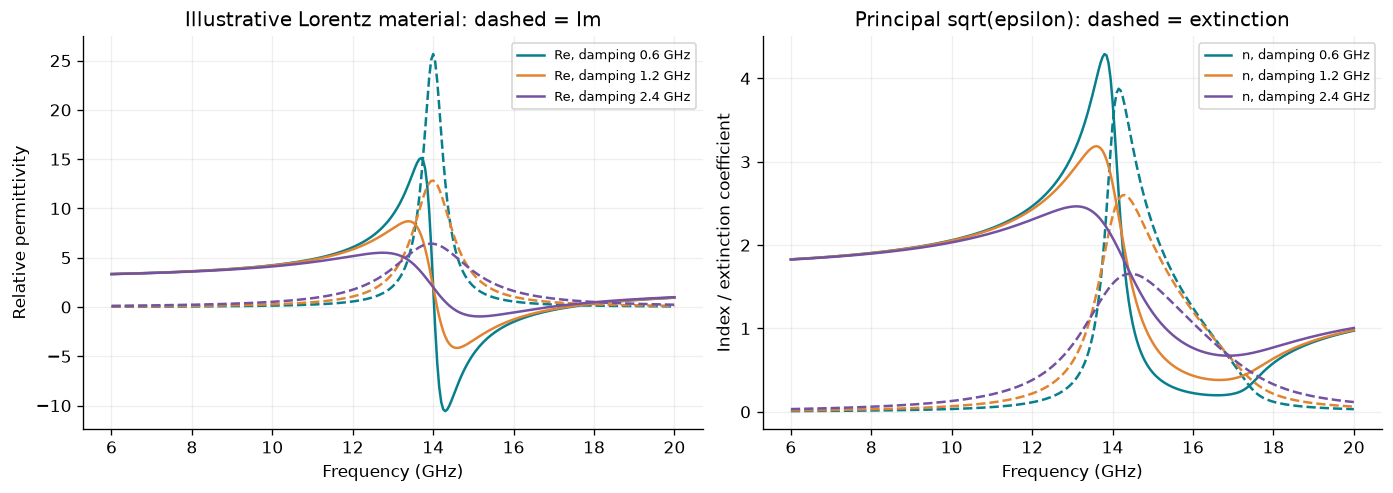

In [2]:
fm=np.linspace(6,20,281);material={}
fig,ax=plt.subplots(1,2,figsize=(11.5,4),layout='constrained')
for damping,color in zip((.6,1.2,2.4),colors):
    eps=lorentz(fm,damping_GHz=damping);index=np.sqrt(eps)
    material[str(damping)]={'epsilon':pack(eps),'index':pack(index)}
    ax[0].plot(fm,eps.real,color=color,label=f'Re, damping {damping} GHz')
    ax[0].plot(fm,eps.imag,'--',color=color)
    ax[1].plot(fm,index.real,color=color,label=f'n, damping {damping} GHz')
    ax[1].plot(fm,index.imag,'--',color=color)
ax[0].set(xlabel='Frequency (GHz)',ylabel='Relative permittivity',title='Illustrative Lorentz material: dashed = Im')
ax[1].set(xlabel='Frequency (GHz)',ylabel='Index / extinction coefficient',title='Principal sqrt(epsilon): dashed = extinction')
for a in ax:a.legend(fontsize=8)
plt.show()
evidence['materials']={'GHz':fm.tolist(),'rows':material,'epsilon_inf':2.,'strength':1.1,'pole_GHz':14.}

## 2. Tolerances, correlation and acceptance

Use 20,000 seeded draws per case. Width and effective permittivity have Gaussian spreads; the resonance follows the local inverse-width and inverse-square-root scaling specified in the chapter. The left panel uses zero width bias. The right panel introduces a common width bias and counts |f₀−10 GHz| ≤ 0.12 GHz. Error bars are 95% Wilson intervals for Monte Carlo sampling error in the assumed population, not confidence in a real process. Common random draws make comparisons less noisy. No samples are silently clipped.

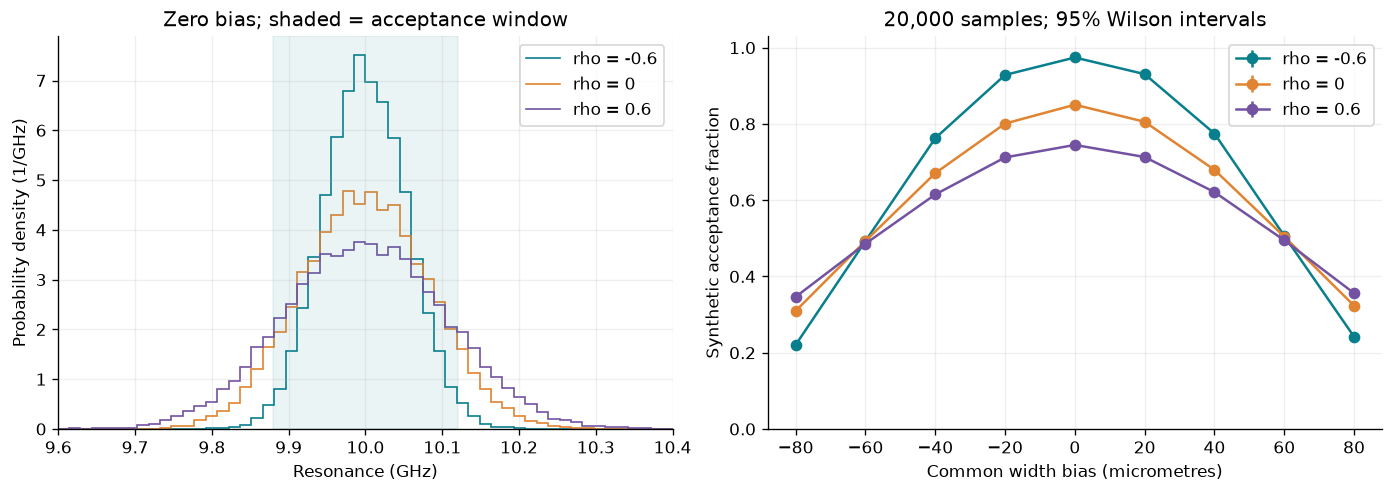

{'-0.6': (0.0539395732548104, 0.05426273532033236), '0.0': (0.08313319494406458, 0.08333333333333334), '0.6': (0.10477704837795587, 0.1046156988431681)}


In [3]:
biases=np.linspace(-.08,.08,9);edges=np.linspace(9.45,10.55,75);tolerance={}
fig,ax=plt.subplots(1,2,figsize=(11.5,4),layout='constrained')
for rho,color in zip((-.6,0.,.6),colors):
    draws=tolerance_samples(rho,p=p);hist,_=np.histogram(draws,bins=edges,density=True)
    rows=[]
    for bias in biases:
        x=tolerance_samples(rho,float(bias),p=p);passed=int(np.count_nonzero(abs(x-p.resonance_GHz)<=p.tolerance_GHz))
        lo,hi=wilson(passed,len(x))
        rows.append({'bias_mm':float(bias),'acceptance':passed/len(x),'low':lo,'high':hi})
    tolerance[str(rho)]={'histogram':hist.tolist(),'std_GHz':float(draws.std(ddof=1)),
        'linear_std_GHz':float(tolerance_linear_std(rho,p)),'rows':rows}
    ax[0].stairs(hist,edges,color=color,label=f'rho = {rho:g}')
    y=np.array([v['acceptance'] for v in rows])
    ax[1].errorbar(biases*1000,y,yerr=[y-[v['low'] for v in rows],[v['high'] for v in rows]-y],
        fmt='o-',color=color,label=f'rho = {rho:g}')
ax[0].axvspan(9.88,10.12,color='#087f8c',alpha=.08)
ax[0].set(xlabel='Resonance (GHz)',ylabel='Probability density (1/GHz)',title='Zero bias; shaded = acceptance window',xlim=(9.6,10.4))
ax[1].set(xlabel='Common width bias (micrometres)',ylabel='Synthetic acceptance fraction',ylim=(0,1.03),
    title='20,000 samples; 95% Wilson intervals')
for a in ax:a.legend()
plt.show()
evidence['tolerance']={'edges_GHz':edges.tolist(),'rows':tolerance,'count':20000}
print({k:(v['std_GHz'],v['linear_std_GHz']) for k,v in tolerance.items()})

## 3. Calibration and the reference plane

The raw complex reading contains directivity, tracking and source-match errors. Exact observations of three ideal known standards recover that error box at every frequency. This corrects the port response, but a 5 mm air-path offset still rotates phase. Divide by the known round-trip factor to reach the surface plane. The magnitude-only view hides this distinction. Noiseless recovery demonstrates the algebra; the next section restores uncertainty. The CSV retains raw readings, the three standard observations and the declared truth for independent reprocessing.

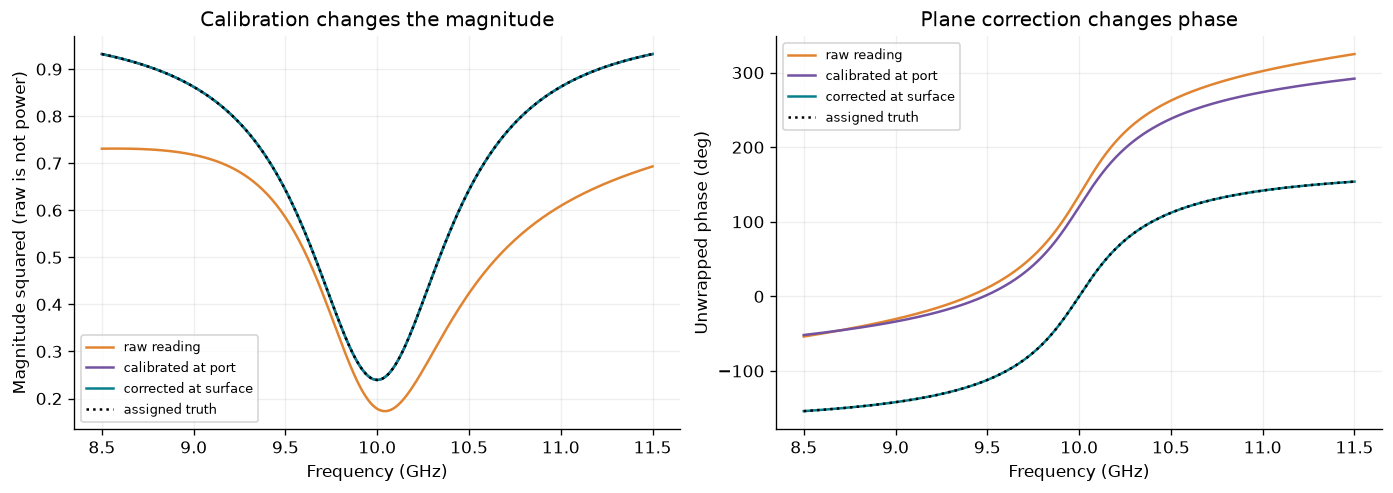

Maximum complex error: 4.742874840267547e-16


In [4]:
f=np.linspace(8.5,11.5,241);sweep=synthetic_sweep(f,p)
fig,ax=plt.subplots(1,2,figsize=(11.5,4),layout='constrained')
for key,label,color,style in [('raw','raw reading',colors[1],'-'),('at_port','calibrated at port',colors[2],'-'),
                             ('recovered','corrected at surface',colors[0],'-')]:
    g=sweep[key];ax[0].plot(f,abs(g)**2,color=color,ls=style,label=label)
    ax[1].plot(f,np.rad2deg(np.unwrap(np.angle(g))),color=color,ls=style,label=label)
ax[0].plot(f,abs(sweep['truth'])**2,'k:',label='assigned truth')
ax[1].plot(f,np.rad2deg(np.unwrap(np.angle(sweep['truth']))),'k:',label='assigned truth')
ax[0].set(xlabel='Frequency (GHz)',ylabel='Magnitude squared (raw is not power)',title='Calibration changes the magnitude')
ax[1].set(xlabel='Frequency (GHz)',ylabel='Unwrapped phase (deg)',title='Plane correction changes phase')
for a in ax:a.legend(fontsize=8)
plt.show()
evidence['calibration']={'GHz':f.tolist(),**{k:pack(v) for k,v in sweep.items() if k!='condition'},
    'max_condition':float(max(sweep['condition']))}
print('Maximum complex error:',max(abs(sweep['recovered']-sweep['truth'])))

## 4. Uncertainty is a region, not a single error bar

Each of 2,000 Monte Carlo trials draws standard-characterization errors, fresh reading noise and sample placement. The ellipse uses the sample covariance and the bivariate-normal 95% threshold 5.991; coverage is approximate for this nonlinear model. The orange cross is the known synthetic truth; it is unavailable in an ordinary experiment.

The right panel is a **separate analytic averaging model**: surface-plane circular noise of total complex RMS 0.002 is independent between readings, while a placement offset stays fixed throughout one batch. Across batches the offset is Gaussian. The displayed complex RMS about truth includes the small nonlinear bias. Calibration-standard uncertainty is not included in this simplified averaging curve. Averaging cannot remove an unknown common phase offset.

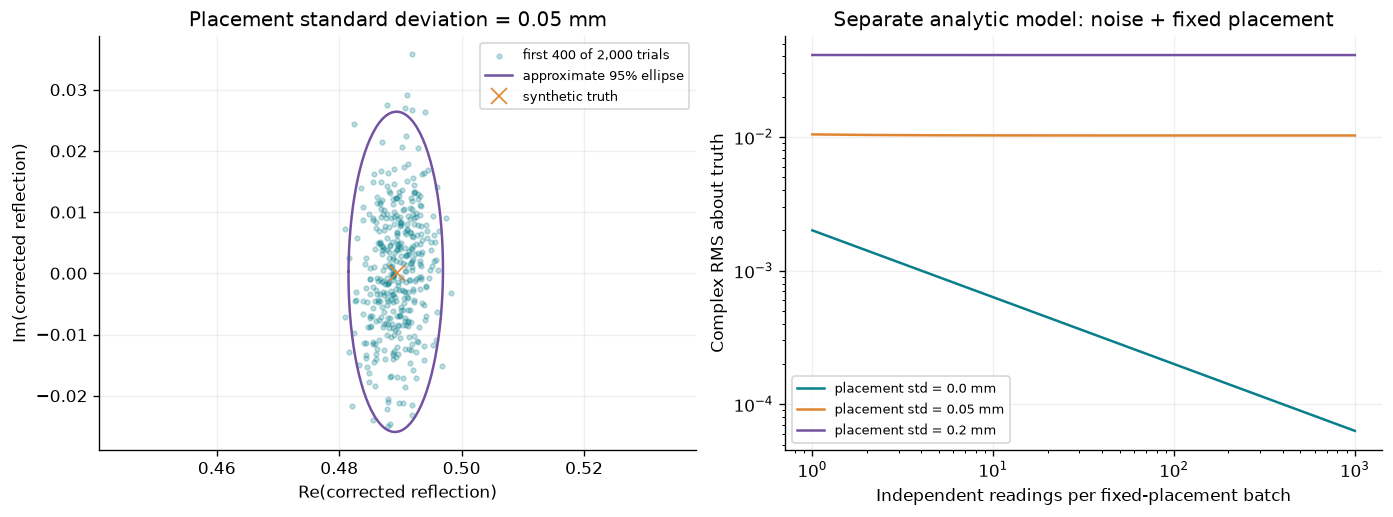

Baseline complex RMS: 0.011143503332402256 Empirical ellipse fraction: 0.9455


In [5]:
truth=complex(reflection(p.resonance_GHz,p=p));uncertainty={}
theta=np.linspace(0,2*np.pi,181);unit=np.array([np.cos(theta),np.sin(theta)])
N=np.unique(np.geomspace(1,1000,80).astype(int))
for position in (0.,.05,.2):
    q=replace(p,position_std_mm=position);g,condition=uncertain_measurements(2000,q)
    xy=np.column_stack([g.real,g.imag]);center=xy.mean(axis=0);cov=np.cov(xy,rowvar=False)
    vals,vec=np.linalg.eigh(cov);ellipse=center[:,None]+vec@np.diag(np.sqrt(-2*np.log(.05)*vals))@unit
    sigma_phase=4*np.pi*p.resonance_GHz*1e9*position*1e-3/C0
    floor2=2*abs(truth)**2*(-np.expm1(-sigma_phase**2/2))
    rms=np.sqrt(p.noise_rms**2/N+floor2)
    delta=xy-center;coverage=np.mean(np.einsum('ni,ij,nj->n',delta,np.linalg.inv(cov),delta)<=-2*np.log(.05))
    uncertainty[str(position)]={'samples':xy[:400].tolist(),'ellipse':ellipse.T.tolist(),
        'center':center.tolist(),'covariance':cov.tolist(),'rms':float(np.sqrt(np.mean(abs(g-truth)**2))),
        'ellipse_sample_fraction':float(coverage),'averaging_rms':rms.tolist(),'floor':float(np.sqrt(floor2))}
fig,ax=plt.subplots(1,2,figsize=(11.5,4.2),layout='constrained')
baseline=uncertainty['0.05'];xy=np.array(baseline['samples']);ellipse=np.array(baseline['ellipse'])
ax[0].scatter(xy[:,0],xy[:,1],s=8,alpha=.25,color=colors[0],label='first 400 of 2,000 trials')
ax[0].plot(ellipse[:,0],ellipse[:,1],color=colors[2],label='approximate 95% ellipse')
ax[0].plot(truth.real,truth.imag,'x',ms=10,color=colors[1],label='synthetic truth')
ax[0].set(xlabel='Re(corrected reflection)',ylabel='Im(corrected reflection)',title='Placement standard deviation = 0.05 mm')
ax[0].axis('equal');ax[0].legend(fontsize=8)
for (key,row),color in zip(uncertainty.items(),colors):
    ax[1].loglog(N,row['averaging_rms'],color=color,label=f'placement std = {key} mm')
ax[1].set(xlabel='Independent readings per fixed-placement batch',ylabel='Complex RMS about truth',
    title='Separate analytic model: noise + fixed placement');ax[1].legend(fontsize=8)
plt.show()
evidence['uncertainty']={'rows':uncertainty,'readings':N.tolist(),'truth':[truth.real,truth.imag],'trials':2000}
print('Baseline complex RMS:',baseline['rms'],'Empirical ellipse fraction:',baseline['ellipse_sample_fraction'])

## 5. Preserve the observations and test independently

Run python scripts/validate_chapter09.py separately. It checks energy balance, independent coupled-mode and error-box expressions, a held-out fourth standard, phase transport, derivative refinement, Monte Carlo versus linear covariance, and invalid inputs.

Challenge the calibration by replacing one known standard with a nearly duplicate response; inspect conditioning. Introduce a common standard phase error or a frequency-correlated drift and compare the uncertainty region. For a real dataset, preserve instrument settings, reference planes, standards' characterized responses, units and raw complex observations before fitting any resonance. Do not call 1−|Γspecular|² absorption when unmeasured scattering channels can carry power.

In [6]:
out=ROOT/'data/chapter-09';out.mkdir(parents=True,exist_ok=True)
(out/'reference.json').write_text(json.dumps(evidence,separators=(',',':'))+'\n',encoding='utf-8')
d,t,s=error_terms(f)
standards=measured(np.array([-1,0,1]),d[:,None],t[:,None],s[:,None])
with (out/'synthetic-sweep.csv').open('w',newline='',encoding='utf-8') as stream:
    writer=csv.writer(stream)
    writer.writerow(['frequency_GHz','raw_re','raw_im','short_re','short_im','load_re','load_im',
                     'open_re','open_im','truth_re','truth_im','offset_mm'])
    for j,freq in enumerate(f):
        values=[freq,sweep['raw'][j].real,sweep['raw'][j].imag]
        for value in standards[j]:values.extend([value.real,value.imag])
        values.extend([sweep['truth'][j].real,sweep['truth'][j].imag,p.offset_mm])
        writer.writerow(values)
print('Saved synthetic observations and reference arrays; no experimental data is represented.')

Saved synthetic observations and reference arrays; no experimental data is represented.
